# Model Training & Evaluation

**Project:** Bank Marketing Campaign Analysis  
**Objective:** Build and compare classification models to predict customer subscription

---

## 1. Setup

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import  RobustScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    roc_auc_score, confusion_matrix, roc_curve, auc
)

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
import xgboost as xgb

# Imbalanced-learn
from imblearn.over_sampling import SMOTE

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("✓ Libraries imported successfully")

✓ Libraries imported successfully


## 2. Load Preprocessed Data

In [2]:
# Load data
df = pd.read_csv('../data/processed/train_preprocessed.csv')

print(f"Dataset shape: {df.shape}")
print(f"\nTarget distribution:")
print(df['subscribed'].value_counts())
print(f"\nClass balance:")
print(df['subscribed'].value_counts(normalize=True) * 100)

Dataset shape: (21573, 30)

Target distribution:
subscribed
0    19015
1     2558
Name: count, dtype: int64

Class balance:
subscribed
0    88.142586
1    11.857414
Name: proportion, dtype: float64


## 3. Data Preparation

We'll prepare our data by:
1. Splitting into features (X) and target (y)
2. Creating train and test sets
3. Handling class imbalance using SMOTE
4. Scaling the features

In [3]:
# Split features and target
X = df.drop(columns=['subscribed'])
y = df['subscribed']

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (19415, 29)
Testing set shape: (2158, 29)


In [4]:
# Handle class imbalance with SMOTE
smote = SMOTE(random_state=42,k_neighbors=5)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

# Scale features
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_balanced)
X_test_scaled = scaler.transform(X_test)

print("Balanced training set shape:", X_train_scaled.shape)
print("Original class distribution:", dict(zip(*np.unique(y_train, return_counts=True))))
print("Balanced class distribution:", dict(zip(*np.unique(y_train_balanced, return_counts=True))))

Balanced training set shape: (34226, 29)
Original class distribution: {0: 17113, 1: 2302}
Balanced class distribution: {0: 17113, 1: 17113}


## 4. Model Training and Evaluation

We'll train multiple models and compare their performance:
1. Logistic Regression (baseline)
2. Random Forest
3. XGBoost
4. LightGBM

In [5]:
# Function to evaluate model performance
def evaluate_model(model, X_train, X_test, y_train, y_test):
    # Train the model
    model.fit(X_train, y_train)
    
    # Make predictions
    y_pred = model.predict(X_test)
    
    # Calculate metrics
    results = {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'auc_roc': roc_auc_score(y_test, y_pred)
    }
    
    return results

# Initialize models
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Random Forest': RandomForestClassifier(    n_estimators=100,
                                                random_state=42,
                                                max_depth=15,
                                                min_samples_split=10,
                                                class_weight='balanced',
                                                n_jobs=-1),
                                                
    'XGBoost': xgb.XGBClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'KNN': KNeighborsClassifier(),
    'Naive Bayes': GaussianNB()
    }

# Train and evaluate each model
results = {}
for name, model in models.items():
    print(f"\nTraining {name}...")
    results[name] = evaluate_model(
        model, X_train_scaled, X_test_scaled, y_train_balanced, y_test
    )
    
# Create results DataFrame
results_df = pd.DataFrame(results).round(4)
print("\nModel Comparison:")
display(results_df)


Training Logistic Regression...

Training Random Forest...

Training Random Forest...

Training XGBoost...

Training XGBoost...

Training Gradient Boosting...

Training Gradient Boosting...

Training AdaBoost...

Training AdaBoost...

Training Decision Tree...

Training Decision Tree...

Training KNN...

Training Naive Bayes...

Model Comparison:

Training KNN...

Training Naive Bayes...

Model Comparison:


,Logistic Regression,Random Forest,XGBoost,Gradient Boosting,AdaBoost,Decision Tree,KNN,Naive Bayes
accuracy,0.8457,0.8920,0.9004,0.8842,0.8897,0.8624,0.8392,0.7057
precision,0.4030,0.5350,0.5872,0.5088,0.5281,0.4361,0.3982,0.2281
recall,0.6250,0.6875,0.5391,0.6797,0.6602,0.5469,0.6953,0.6211
f1,0.4900,0.6017,0.5621,0.5819,0.5868,0.4853,0.5064,0.3337
auc_roc,0.7502,0.8035,0.7440,0.7957,0.7904,0.7259,0.7769,0.6691


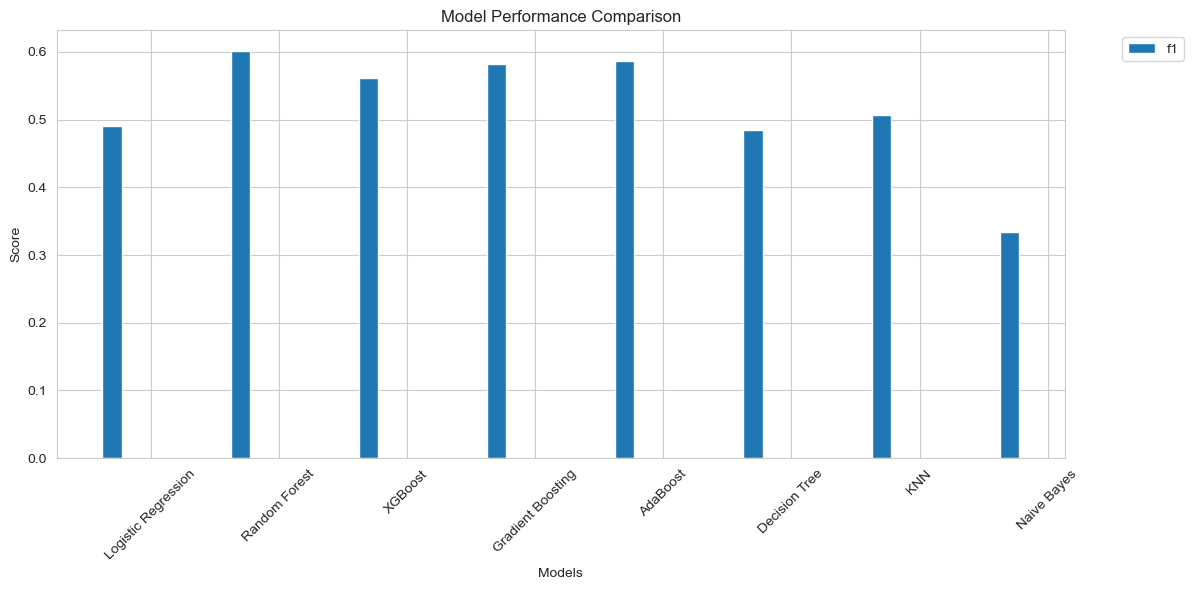

In [6]:
# Visualize results
plt.figure(figsize=(12, 6))
metrics = [ 'f1']
x = np.arange(len(models))
width = 0.15
multiplier = 0

for metric in metrics:
    offset = width * multiplier
    plt.bar(x + offset, results_df.loc[metric], width, label=metric)
    multiplier += 1

plt.xlabel('Models')
plt.ylabel('Score')
plt.title('Model Performance Comparison')
plt.xticks(x + width * 2, models.keys(), rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 5. Best Model Analysis

Let's analyze the best performing model in more detail by:
1. Plotting confusion matrix
2. ROC curve
3. Feature importance (if applicable)

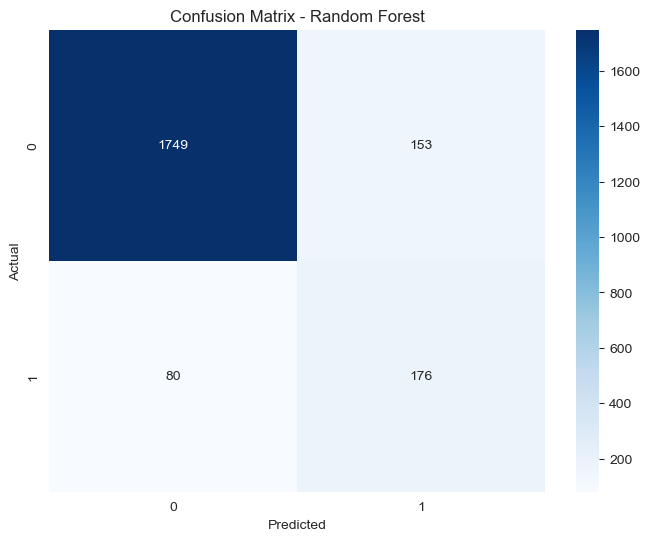

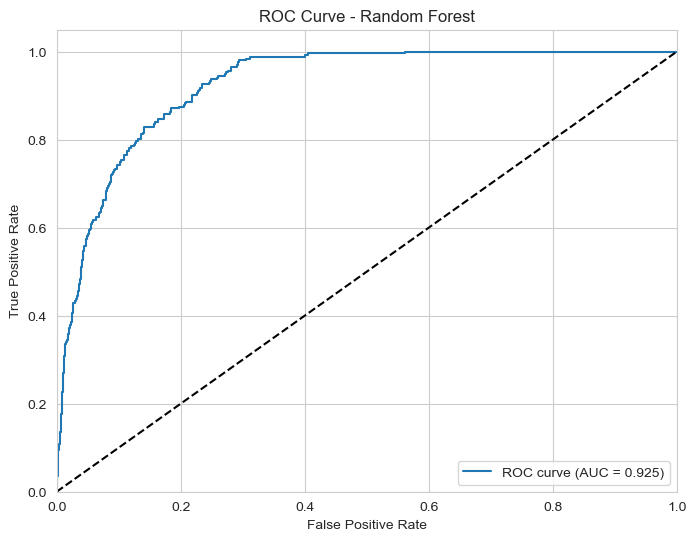

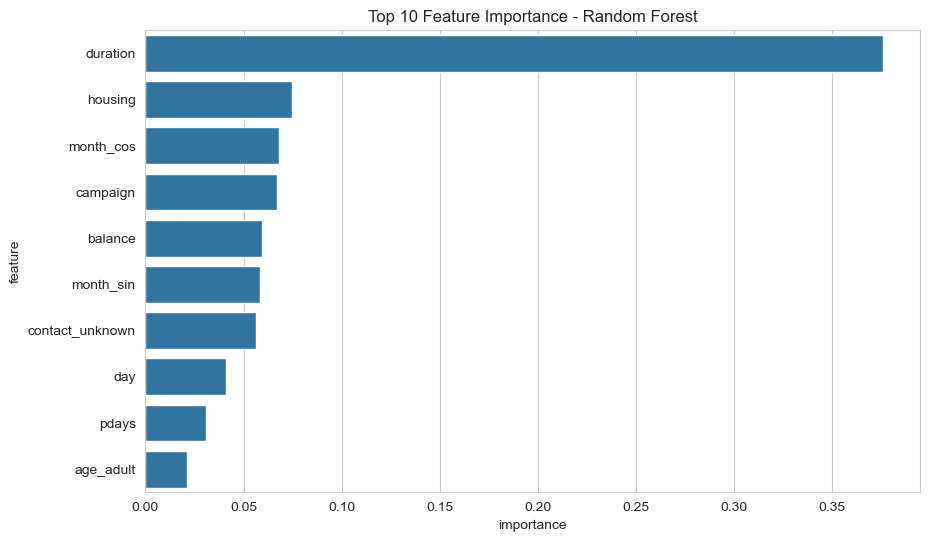

In [7]:
# Get best model based on F1 score
best_model_name = results_df.loc['f1'].idxmax()
best_model = models[best_model_name]

# Get predictions
y_pred = best_model.predict(X_test_scaled)
y_pred_proba = best_model.predict_proba(X_test_scaled)[:, 1]

# Plot confusion matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Plot ROC curve
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc(fpr, tpr):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curve - {best_model_name}')
plt.legend(loc="lower right")
plt.show()

# Feature importance (if applicable)
if hasattr(best_model, 'feature_importances_'):
    importances = pd.DataFrame({
        'feature': X.columns,
        'importance': best_model.feature_importances_
    }).sort_values('importance', ascending=False)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(x='importance', y='feature', data=importances.head(10))
    plt.title(f'Top 10 Feature Importance - {best_model_name}')
    plt.show()